# Evaluate Posterior Density Estimator

In [4]:
import numpy as np
import torch
import math
import matplotlib.pyplot as plt
import pickle
import os

from omegaconf import OmegaConf
from multiprocessing import Pool
from collections import defaultdict
from tqdm import tqdm
from scipy.stats import kstest

from sbi import utils as utils
from sbi import analysis as analysis
from sbi.inference.posteriors import DirectPosterior
from sbi.utils import within_support
from sbi.analysis.plot import sbc_rank_plot

import sys
from pathlib import Path

project_root = Path.cwd().resolve().parent if Path.cwd().name == "analysis" else Path.cwd().resolve()
src_dir = project_root / "src"
if str(src_dir) not in sys.path:
    sys.path.append(str(src_dir))

from simulator import smFRET_simulator_wrapper_from_config, binding_simulator_wrapper_from_config
from priors import (
    generate_fret_prior_from_config,
    generate_split_priors_from_config,
    assemble_canonical_theta,
    PHYS_PARAM_NAMES,
)
from utils import eval_free_energy_from_config, eval_force_from_config
from utils import map_with_cached_embedding
from data_loaders import H5Dataset


## Configuration

In [41]:
# Paths
cfg_path = "/home/dingeldein/Desktop/fret_sbi/smFRET_sbi/outputs/2026-05-27/11-51-26/"
device = "cuda" if torch.cuda.is_available() else "cpu"

# Ground-truth canonical params (length = num_knots + 9):
#   [logD, g_0..g_{n-1}, R0, kD, k_gb, k_rb, eta_g, eta_r, C_gr, C_rg]
# This run has num_knots=7; knot values mirror the prior center.
# Set explicit values, or leave as None to sample from the simulation prior.
true_params = torch.tensor(
    [0.75,  3.0, -3.0, -2.0, 0.0, 2.0, 3.0, -3.0,  6.0,  400.0, 0.0, 0.0, 1.0, 1.0, 0.0, 0.0],
    dtype=torch.float64,
)

# Observation settings
n_observations = 25
n_simulations_pool = 200
ppc_simulations_pool = 5000

# Posterior sampling
num_posterior_samples = 5000
posterior_batch_size = 1000

# MAP estimation
map_num_iter = 4000
map_learning_rate = 0.005
map_num_init_samples = 5

# SBC settings
sbc_num_runs = 800
sbc_batch_size = 5
sbc_num_posterior_samples = 1000
sbc_n_workers = 20

## Load Prior, Simulator, and Model

In [27]:
data_cfg_path = cfg_path + "data_config.yaml"
data_cfg = OmegaConf.load(data_cfg_path)

prior_sim = generate_fret_prior_from_config(data_cfg_path, device=device)
inferred_prior, nuisance_prior, inferred_idx, nuisance_idx = (
    generate_split_priors_from_config(data_cfg_path, device=device)
)

eval_force = eval_force_from_config(data_cfg_path)
eval_free_energy = eval_free_energy_from_config(data_cfg_path)

num_knots = data_cfg.prior.num_knots
canonical_dim = num_knots + 9                       # full theta length
theta_dim = int(inferred_idx.numel())               # NPE output dimension

# Human-readable labels for the inferred subset
_TOK_NAMES = ["logD"] + [f"g{i}" for i in range(num_knots)] + list(PHYS_PARAM_NAMES)
inferred_labels = [_TOK_NAMES[i] for i in inferred_idx.tolist()]

print(f"Inferred params ({theta_dim}): {inferred_labels}")
print(f"Inferred idx (canonical positions): {inferred_idx.tolist()}")

if true_params is None:
    true_params = prior_sim.sample((1,)).squeeze(0).cpu().double()
    print(f"Sampled true_params ({len(true_params)} dims)")
print(f"  inferred slice: {true_params[inferred_idx].numpy().round(3)}")
print(f"  logD={true_params[0]:.3f}, R0={true_params[num_knots+1]:.3f}")

# ---------------------------------------------------------------------------
# Simulator: wraps Cython binding/equilibrium sim and converts the per-photon
# event output (ipt, chans, length) into the 4-channel model input format
# (log(ipt+eps), G_onehot, R_onehot, mask) -- same convention as the training
# data loader (data_loaders.H5Dataset._arrivals_to_x).
# ---------------------------------------------------------------------------
LOG_IPT_EPS = H5Dataset.LOG_IPT_EPS

if data_cfg.simulator.mode == "equilibrium":
    _fret_simulator = smFRET_simulator_wrapper_from_config(data_cfg_path)
elif data_cfg.simulator.mode == "binding":
    _fret_simulator = binding_simulator_wrapper_from_config(data_cfg_path)
else:
    raise ValueError(f"Unknown simulator.mode: {data_cfg.simulator.mode!r}")


def _arrivals_to_x_single(ipt, chans, length):
    """Per-photon (ipt, chans, length) -> (N_max, 4) tensor (log_ipt, G, R, mask)."""
    ipt = ipt.detach().cpu().numpy() if torch.is_tensor(ipt) else np.asarray(ipt)
    chans = chans.detach().cpu().numpy() if torch.is_tensor(chans) else np.asarray(chans)
    length = np.asarray([int(length)], dtype=np.int64)
    x = H5Dataset._arrivals_to_x(ipt[None, :], chans[None, :], length)
    return x[0]


def fret_simulator(params):
    """Wraps the Cython sim to yield a (N_max, 4) tensor or None on failure."""
    result = _fret_simulator(params)
    if result is None:
        return None
    ipt, chans, length = result
    return _arrivals_to_x_single(ipt, chans, length)


Inferred params (7): ['g0', 'g1', 'g2', 'g3', 'g4', 'g5', 'g6']
Inferred idx (canonical positions): [1, 2, 3, 4, 5, 6, 7]
  inferred slice: [ 3. -3. -2.  0.  2.  3. -3.]
  logD=0.750, R0=6.000


In [28]:
assert within_support(prior_sim, true_params.unsqueeze(0).to(device)).item(), (
    "Ground-truth parameters fall outside the simulation prior's support."
)


In [29]:
_estimator_candidates = [
    "npe_density_estimator.pkl",
    "last_npe_density_estimator.pkl",
    "npe_set_estimator.pkl",        # legacy name
    "last_npe_set_estimator.pkl",   # legacy name
]
for fname in _estimator_candidates:
    fpath = cfg_path + fname
    if os.path.exists(fpath):
        with open(fpath, "rb") as f:
            density_estimator = pickle.load(f)
        print(f"Loaded density estimator from {fname}")
        break
else:
    raise FileNotFoundError(
        f"No density estimator pickle found in {cfg_path}. "
        f"Looked for: {_estimator_candidates}"
    )

density_estimator = density_estimator.to(device)
density_estimator.eval();


Loaded density estimator from npe_density_estimator.pkl


In [30]:
def _init_worker():
    np.random.seed(os.getpid())


def _photon_trace_to_time_bins(trace, n_bins=100):
    """(N_max, 4) photon-event tensor -> (n_bins,) donor/acceptor counts.

    Recovers per-photon arrival times by cumulating ipt = exp(log_ipt) - eps
    over the masked region, then histograms photons by time into ``n_bins``
    equal-width bins.
    """
    if torch.is_tensor(trace):
        trace = trace.cpu().numpy()
    mask = trace[:, 3].astype(bool)
    if not mask.any():
        z = np.zeros(n_bins)
        return z, z
    log_ipt = trace[mask, 0]
    g_oh = trace[mask, 1] > 0.5
    r_oh = trace[mask, 2] > 0.5
    ipt = np.exp(log_ipt) - LOG_IPT_EPS
    ipt = np.clip(ipt, 0.0, None)
    t = np.cumsum(ipt)
    if t[-1] <= 0:
        z = np.zeros(n_bins)
        return z, z
    edges = np.linspace(0.0, t[-1], n_bins + 1)
    donor, _ = np.histogram(t[g_oh], bins=edges)
    acceptor, _ = np.histogram(t[r_oh], bins=edges)
    return donor, acceptor


## Ground-Truth Free Energy

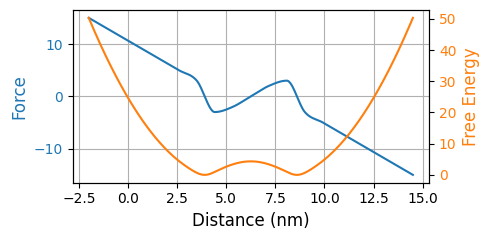

In [31]:
knot_spacing = (data_cfg.simulator.x_max - data_cfg.simulator.x_min) / (data_cfg.prior.num_knots - 1)
x_plot_margin = 0.6 * data_cfg.simulator.num_boundary_knots * knot_spacing
x_eval = np.linspace(
    data_cfg.simulator.x_min - x_plot_margin,
    data_cfg.simulator.x_max + x_plot_margin,
    500,
)

fig, ax1 = plt.subplots(figsize=(5, 2.5), sharex=True)

x, y_force = eval_force(params=true_params, x_eval=x_eval)
ax1.plot(x, y_force, color="tab:blue", label="Force")
ax1.set_xlabel("Distance (nm)", fontsize=12)
ax1.set_ylabel("Force", color="tab:blue", fontsize=12)
ax1.tick_params(axis="y", labelcolor="tab:blue")
ax1.grid()

ax2 = ax1.twinx()
x, y_free_energy = eval_free_energy(params=true_params, x_eval=x_eval)
ax2.plot(x, y_free_energy - np.min(y_free_energy), color="tab:orange", label="Free Energy")
ax2.set_ylabel("Free Energy", color="tab:orange", fontsize=12)
ax2.tick_params(axis="y", labelcolor="tab:orange")

plt.tight_layout()


## Simulate Observations

In [32]:
with Pool(processes=24, initializer=_init_worker) as pool:
    raw = pool.map(fret_simulator, [true_params] * n_simulations_pool)
results = [r for r in raw if r is not None][:n_observations]
observation = torch.stack(results).unsqueeze(0)  # (1, N, N_max, 4)
print(f"Observation shape: {observation.shape}  (expected: (1, {n_observations}, N_max, 4))")


Observation shape: torch.Size([1, 25, 5000, 4])  (expected: (1, 25, N_max, 4))


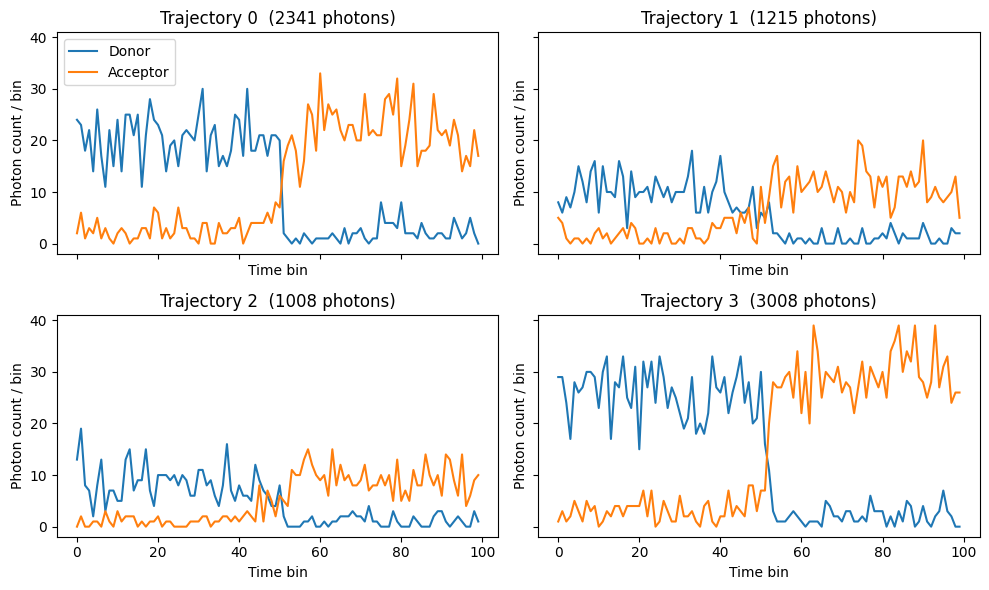

In [33]:
n_show = min(4, observation.shape[1])
idxs = list(range(n_show))

fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True, sharey=True)

for ax, idx in zip(axes.ravel(), idxs):
    trace = observation[0, idx]  # (N_max, 4)
    n_photons = int(trace[:, 3].sum().item())
    donor, acceptor = _photon_trace_to_time_bins(trace, n_bins=100)
    ax.plot(donor, label="Donor")
    ax.plot(acceptor, label="Acceptor")
    ax.set_title(f"Trajectory {idx}  ({n_photons} photons)")
    ax.set_ylabel("Photon count / bin")
    ax.set_xlabel("Time bin")

axes[0, 0].legend()
plt.tight_layout()


## Posterior Inference

In [34]:
posterior = DirectPosterior(density_estimator, prior=inferred_prior)
obs = observation.to(device)

samples = posterior.sample(
    (num_posterior_samples,),
    x=obs,
    max_sampling_batch_size=posterior_batch_size,
).cpu()

print(f"Samples shape: {samples.shape}  (expected: [{num_posterior_samples}, {theta_dim}])")


  0%|          | 0/5000 [00:00<?, ?it/s]/home/dingeldein/Venvs/fret_sbi/lib/python3.10/site-packages/nflows/transforms/lu.py:80: UserWarning: torch.triangular_solve is deprecated in favor of torch.linalg.solve_triangularand will be removed in a future PyTorch release.
torch.linalg.solve_triangular has its arguments reversed and does not return a copy of one of the inputs.
X = torch.triangular_solve(B, A).solution
should be replaced with
X = torch.linalg.solve_triangular(A, B). (Triggered internally at ../aten/src/ATen/native/BatchLinearAlgebra.cpp:2190.)
  outputs, _ = torch.triangular_solve(
5067it [00:04, 1097.05it/s]                          

Samples shape: torch.Size([5000, 7])  (expected: [5000, 7])


In [35]:
log_prob_batch_size = 10

samples_dev = samples.to(device)
log_probs = []
with torch.no_grad():
    for start in tqdm(range(0, samples_dev.shape[0], log_prob_batch_size), desc="log_prob batches"):
        chunk = samples_dev[start:start + log_prob_batch_size]
        lp = posterior.log_prob(chunk, x=obs)
        log_probs.append(lp.cpu())
log_probs = torch.cat(log_probs)

print(f"log_probs shape: {log_probs.shape}  (expected: [{num_posterior_samples}])")
print(f"  min={log_probs.min().item():.3f}  max={log_probs.max().item():.3f}  mean={log_probs.mean().item():.3f}")


log_prob batches: 100%|██████████| 500/500 [02:01<00:00,  4.11it/s]

log_probs shape: torch.Size([5000])  (expected: [5000])
  min=-15.766  max=-2.270  mean=-5.435


In [42]:
top_k = 500

top_log_probs, top_idx = torch.topk(log_probs, k=top_k)
top_samples = samples[top_idx]


In [43]:
map_estimate = map_with_cached_embedding(
    density_estimator=density_estimator,
    prior=inferred_prior,
    x=obs,
    num_iter=map_num_iter,
    num_init_samples=top_samples.shape[0],
    num_to_optimize=top_samples.shape[0],
    learning_rate=map_learning_rate,
    init_samples=top_samples,
    show_progress_bars=True,
)


 Optimizing MAP estimate. Iterations: 2011 / 4000. Performance in iteration 2010: -0.78 (= unnormalized log-prob). Press Ctrl-C to interrupt.Optimization was interrupted after 2011 iterations. 


## Results

/tmp/ipykernel_367935/501129267.py:17: DeprecationWarning: you passed deprecated arguments **kwargs: ['points_offdiag', 'points_colors'], use fig_kwargs instead. We continue calling the deprecated pairplot function
  _ = analysis.pairplot(


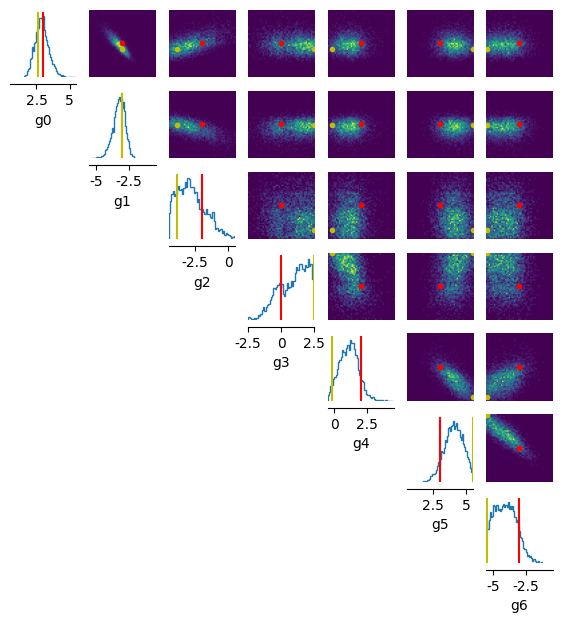

In [44]:
# Build per-parameter limits for the inferred subset.
# Canonical idx -> (low, high) prior bounds.
scale = data_cfg.prior.scale
center = list(data_cfg.prior.center) if data_cfg.prior.center is not None else [0.0] * num_knots

def _bounds_for_canonical(i):
    if i == 0:
        return list(data_cfg.prior.logD_lims)
    if 1 <= i <= num_knots:
        c = center[i - 1]
        return [c - scale, c + scale]
    phys_name = PHYS_PARAM_NAMES[i - num_knots - 1]
    return list(data_cfg.prior[f"{phys_name}_lims"])

limits = [_bounds_for_canonical(int(i)) for i in inferred_idx.tolist()]

_ = analysis.pairplot(
    samples,
    figsize=(7, 7),
    points=[true_params[inferred_idx].float(), map_estimate[0].cpu()],
    points_offdiag={"markersize": 6},
    points_colors=["r", "y"],
    limits=limits,
    labels=inferred_labels,
)


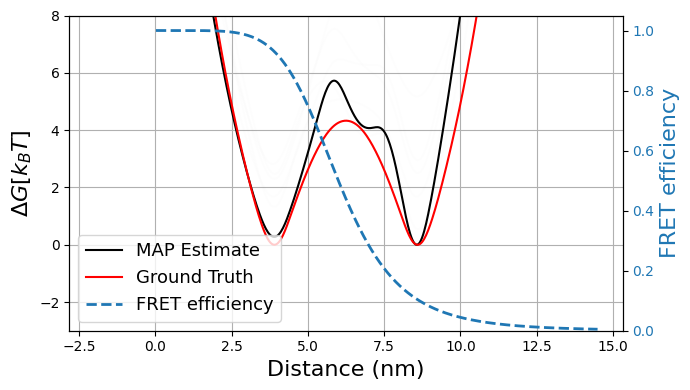

In [40]:
# eval_free_energy/eval_force read logD at params[0] and g_i at params[1:num_knots+1];
# the inferred sample carries those at positions matching canonical idx 0..num_knots
# whenever inferred_params starts with [logD, knots] (the standard config). For the
# generic case, scatter into a canonical-shaped vector using inferred_idx.

def _to_canonical(theta_inferred):
    """Place a (theta_dim,) inferred sample into a (canonical_dim,) zero-padded vector."""
    out = torch.zeros(canonical_dim, dtype=theta_inferred.dtype)
    out[inferred_idx] = theta_inferred.to(out.dtype)
    return out


fig, ax1 = plt.subplots(figsize=(7, 4))

# MAP free-energy (reference for alignment)
map_canonical = _to_canonical(map_estimate[0].cpu())
x, y_map = eval_free_energy(params=map_canonical, x_eval=x_eval)
y_map_shifted = y_map - y_map.min()

# Free-energy samples — align each to MAP via least-squares vertical shift
# (free energy defined up to additive constant).
for i in range(min(5, samples.shape[0])):
    x, y = eval_free_energy(params=_to_canonical(samples[i]), x_eval=x_eval)
    offset = np.mean(y_map_shifted - y)
    ax1.plot(x, y + offset, color="gray", alpha=0.01)

ax1.plot(x, y_map_shifted, color="black", label="MAP Estimate")

# Ground-truth free-energy (aligned to MAP)
x, y_true = eval_free_energy(params=true_params, x_eval=x_eval)
offset_true = np.mean(y_true - y_map_shifted)
ax1.plot(x, y_true - min(y_true) , color="r", label="Ground Truth")

ax1.set_xlabel("Distance (nm)", fontsize=16)
ax1.set_ylabel(r"$\Delta G [k_{B}T]$", fontsize=16)
ax1.set_ylim(-3, 8)
ax1.grid()

# Secondary axis: FRET efficiency under ground-truth R0
ax2 = ax1.twinx()
R0 = float(true_params[num_knots + 1])
r = np.clip(x_eval, 1e-9, None)
E = 1.0 / (1.0 + (r / R0) ** 6)
E[x_eval <= 0] = np.nan

ax2.plot(x_eval, E, color="tab:blue", linestyle="--", linewidth=2, label="FRET efficiency")
ax2.set_ylabel("FRET efficiency", color="tab:blue", fontsize=16)
ax2.set_ylim(0, 1.05)
ax2.tick_params(axis="y", labelcolor="tab:blue")

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, fontsize=13, loc="best")

plt.tight_layout()


## Pooled FRET-efficiency PPC

Compare the pooled distribution of $E(t) = n_R / (n_R + n_G)$ between the
observation and a MAP-predictive simulation.  Model-free, shot-noise-tolerant
check that the inferred free energy reproduces the basin populations.


In [ ]:
def _trace_to_E_photons(trace, k_smooth=50):
    """Per-photon FRET efficiency via sliding window over consecutive photons.

    Input trace is the (N_max, 4) photon-event tensor; mask channel selects
    real photons. Returns E values of length (n_valid - k_smooth + 1).
    """
    if torch.is_tensor(trace):
        trace = trace.cpu().numpy()
    mask = trace[:, 3].astype(bool)
    if mask.sum() < k_smooth:
        return np.array([], dtype=np.float32)
    g = trace[mask, 1].astype(np.float32)
    r = trace[mask, 2].astype(np.float32)
    kernel = np.ones(k_smooth, dtype=np.float32)
    g_smooth = np.convolve(g, kernel, mode="valid")
    r_smooth = np.convolve(r, kernel, mode="valid")
    total = g_smooth + r_smooth
    with np.errstate(invalid="ignore", divide="ignore"):
        E = np.where(total > 0, r_smooth / np.maximum(total, 1e-12), np.nan)
    return E


# Window in photons. Sliding ~50 photons gives a stable per-window E estimate;
# tune to taste — small windows track fast dynamics but are shot-noise heavy.
k_smooth = 50

# MAP-predictive simulation: scatter MAP (inferred dims) into canonical theta,
# fill nuisance positions afresh from the simulation prior on every call so the
# PPC marginalises over nuisances.
map_inferred = map_estimate[0].cpu().double()
params_list = []
for _ in range(n_simulations_pool):
    p_full = prior_sim.sample((1,)).squeeze().cpu().double().clone()
    p_full[inferred_idx] = map_inferred
    params_list.append(p_full)

with Pool(processes=24, initializer=_init_worker) as pool:
    raw_map = pool.map(fret_simulator, params_list)
map_results = [r for r in raw_map if r is not None][:n_observations]
map_observation = torch.stack(map_results)
print(f"MAP-predictive shape: {map_observation.shape}")

E_obs = np.concatenate([_trace_to_E_photons(observation[0, i], k_smooth=k_smooth) for i in range(observation.shape[1])])
E_map = np.concatenate([_trace_to_E_photons(map_observation[i], k_smooth=k_smooth) for i in range(map_observation.shape[0])])
E_obs = E_obs[np.isfinite(E_obs)]
E_map = E_map[np.isfinite(E_map)]

fig, ax = plt.subplots(figsize=(7, 4))
bins = np.linspace(0, 1, 81)
ax.hist(E_obs, bins=bins, density=True, histtype="step", color="r",
        linewidth=2, label=f"Ground Truth  N={E_obs.size}")
ax.hist(E_map, bins=bins, density=True, histtype="step", color="black",
        linewidth=2, label=f"MAP (prior nuisances)  N={E_map.size}")
ax.set_xlabel("E  (FRET efficiency)", fontsize=14)
ax.set_ylabel("density", fontsize=14)
ax.set_title(f"Pooled FRET-efficiency PPC  (k_smooth={k_smooth} photons)")
ax.legend(fontsize=11)
ax.grid()
plt.tight_layout()


## Simulation-Based Calibration (SBC)

Test posterior calibration by repeatedly:
1. Drawing parameters from the prior
2. Simulating observations with those parameters
3. Sampling from the posterior conditioned on the observations
4. Computing the rank of the true parameters among the posterior samples

Well-calibrated posteriors produce uniformly distributed ranks.

In [ ]:
def run_sbc_batch(
    batch_size, n_trials, prior_sim, inferred_prior, inferred_idx,
    simulator_fn, density_estimator, n_simulations_pool, n_workers,
    n_posterior_samples, device, posterior_batch_size=1000,
):
    """One SBC batch: simulate observations, sample posteriors, compute ranks.

    The simulator consumes a full canonical theta; the posterior is over the
    ``inferred_idx`` slice. Ranks are computed by counting how many posterior
    samples fall below the ground-truth value, per inferred dimension.
    """
    theta_dim = int(inferred_idx.numel())

    # 1. Sample canonical thetas from the full simulation prior
    thetas = [prior_sim.sample((1,)).squeeze(0).cpu().double() for _ in range(batch_size)]

    # 2. Flatten simulator tasks (n_simulations_pool attempts per run)
    n_attempts = n_simulations_pool
    tasks = []
    task_run_idx = []
    for run_idx, theta in enumerate(thetas):
        tasks.extend([theta] * n_attempts)
        task_run_idx.extend([run_idx] * n_attempts)

    with Pool(processes=n_workers, initializer=_init_worker) as pool:
        raw_results = pool.map(simulator_fn, tasks)

    # 3. Group by run, filter failures, keep n_trials valid traces per run
    grouped = defaultdict(list)
    for idx, result in zip(task_run_idx, raw_results):
        if result is not None:
            grouped[idx].append(result)

    # 4. Per valid run: build observation set, sample posterior, compute ranks
    all_thetas = []
    all_ranks = []
    for run_idx in range(batch_size):
        results = grouped[run_idx][:n_trials]
        if len(results) < n_trials:
            continue

        obs = torch.stack(results).unsqueeze(0).to(device)  # (1, n_trials, N_max, 4)

        posterior = DirectPosterior(density_estimator, prior=inferred_prior)
        samples = posterior.sample(
            (n_posterior_samples,),
            x=obs,
            max_sampling_batch_size=posterior_batch_size,
        ).cpu()

        theta_reduced = thetas[run_idx][inferred_idx].float()
        ranks = (samples.float() < theta_reduced.unsqueeze(0)).sum(dim=0)
        all_thetas.append(theta_reduced)
        all_ranks.append(ranks)

    if len(all_thetas) == 0:
        return torch.empty(0, theta_dim), torch.empty(0, theta_dim, dtype=torch.long)
    return torch.stack(all_thetas), torch.stack(all_ranks)


In [ ]:
n_batches = math.ceil(sbc_num_runs / sbc_batch_size)
total_sims = sbc_num_runs * n_simulations_pool
print(f"SBC: {sbc_num_runs} runs x {n_simulations_pool} simulations = {total_sims} total simulations")
print(f"     {n_batches} batches of up to {sbc_batch_size} runs each")

all_thetas, all_ranks = [], []
for b in tqdm(range(n_batches), desc="SBC batches"):
    batch_n = min(sbc_batch_size, sbc_num_runs - b * sbc_batch_size)
    thetas, ranks = run_sbc_batch(
        batch_size=batch_n,
        n_trials=n_observations,
        prior_sim=prior_sim,
        inferred_prior=inferred_prior,
        inferred_idx=inferred_idx,
        simulator_fn=fret_simulator,
        density_estimator=density_estimator,
        n_simulations_pool=n_simulations_pool,
        n_workers=sbc_n_workers,
        n_posterior_samples=sbc_num_posterior_samples,
        device=device,
        posterior_batch_size=posterior_batch_size,
    )
    all_thetas.append(thetas)
    all_ranks.append(ranks)

sbc_thetas = torch.cat(all_thetas)
sbc_ranks = torch.cat(all_ranks)
print(f"Completed {sbc_ranks.shape[0]}/{sbc_num_runs} valid SBC runs")


In [ ]:
sbc_rank_plot(
    sbc_ranks,
    num_posterior_samples=sbc_num_posterior_samples,
    plot_type="cdf",
    parameter_labels=inferred_labels,
)
plt.tight_layout()


In [ ]:
normalized = sbc_ranks.float() / sbc_num_posterior_samples
ks_pvals = [kstest(normalized[:, p].numpy(), "uniform").pvalue for p in range(theta_dim)]

print("KS uniformity test (p > 0.05 = pass):")
for name, pval in zip(inferred_labels, ks_pvals):
    status = "PASS" if pval > 0.05 else "FAIL"
    print(f"  {name:>6s}: p = {pval:.4f}  [{status}]")

n_pass = sum(p > 0.05 for p in ks_pvals)
print(f"\n{n_pass}/{theta_dim} parameters pass uniformity test")


In [ ]:
sbc_out = {"thetas": sbc_thetas, "ranks": sbc_ranks, "inferred_idx": inferred_idx.cpu()}
with open(cfg_path + "sbc_results.pkl", "wb") as f:
    pickle.dump(sbc_out, f)
print(f"Saved SBC results to {cfg_path}sbc_results.pkl")
